<img src="https://www.anped.org.br/sites/default/files/images/ufcg-lateral.png" width="780" height="240" align="center"/>

## Centro de Engenharia Elétrica e Informática
## Departamento de Engenharia Elétrica
## Disciplina: <span style='color:red'>Int. ao Processamento de Imagem Digital e Visão Computacional</span>
## Professora: <span style='color:red'>Luciana Veloso</span>
## Aluno(a): <span style='color:red'>Alysson Machado de Oliveira Barbosa</span>

# <span style='color:brown'>Experimento 02: Processamento Digital de Imagens</span>
***

## Sumário de Conteúdos 
* [0. Importação dos Pacotes](#0)
* [1. Adição de Ruído a Image](#1)
* [2. Transformação de Potência](#2)
* [3. Alargamento de Contraste](#3)
* [4. Transformações Logarítmicas](#4)
* [5. Cálculo de Histogramas](#5)
* [6. Equalização de Histograma](#6) 
* [7. Filtragem Espacial](#7) 
* [8. Suavização de Imagens](#8)
* [9. Aguçamento de Imagens](#9)

## <span style='color:brown'>0. Importação dos Pacotes</span> <a class="anchor" id="0"></a>
***

In [1]:
import cv2 as cv                     
import numpy as np                   
import matplotlib.pyplot as plt      
import random
import math

## <span style='color:brown'>1. Adição de ruído a imagem</span> <a class="anchor" id="1"></a>
***

O ruído em uma imagem é apenas uma espécie de interferência que se manifesta sob a forma de pixels de cores bem diferentes da realidade. Tecnicamente, ruído é descrito como uma variação aleatória do brilho ou cor. Um ruído comum de ocorrem em imagens digitais é o chamado ruído sal e pimenta, na qual se caracteriza como pontos aleatórios na imagem de cor preta e branca (valores extremos de intensidade na imagem).

In [2]:
def sp_noise(image, prob):
    
    output = np.zeros(image.shape, np.uint8)
    thres = 1 - prob 
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            rdn = random.random()
            if rdn < prob:
                output[i][j] = 0
            elif rdn > thres:
                output[i][j] = 255
            else:
                output[i][j] = image[i][j]
                
    return output

Text(0.5, 1.0, 'Imagem com Ruído (prob = 0.1)')

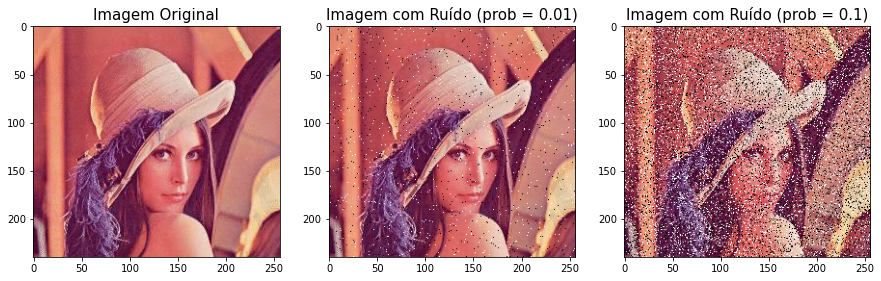

In [220]:
img = cv.imread('lenna.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB) 

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(15, 15))

axs[0].imshow(img)
axs[0].set_title('Imagem Original', size=15)
img_noise = sp_noise(image=img, prob=0.01)
axs[1].imshow(img_noise)
axs[1].set_title('Imagem com Ruído (prob = 0.01)', size=15)
img_noise = sp_noise(image=img, prob=0.1)
axs[2].imshow(img_noise)
axs[2].set_title('Imagem com Ruído (prob = 0.1)', size=15)

##  <span style='color:brown'>2. Transformação de potência<span> <a class="anchor" id="2"></a>
***

Os pixels de uma imagem podem ser submetidos a uma função de transformação ponto-a-ponto, da forma $y = x^γ$ , onde um fator $γ$ positivo e maior que $1$ produzirá uma imagem resultante mais escura que a imagem original, enquanto um fator $γ$ entre $0$ e $1$ produzirá uma imagem resultante mais clara que a imagem original. No python essa função de transformação  está disponível através da função **intensity_transform.gammaCorrection** da biblioteca do OpenCv

**Sintaxe:** `cv.intensity_transform.gammaCorrection(img_in, img_out, gamma)`

**Descrição:** Dada uma imagem colorida (BGR) ou em tons de cinza de entrada e a constante gama, aplique a transformação de lei de potência, também conhecida como correção de gama à imagem no domínio [0, 255] e retorne a imagem resultante.

**Obs.:** Antes de executar essa função é necessário definir a imagem de entrada. Você pode usar o seguinte comando:

`img_out = np.zeros (img_in.shape, img_in.dtype)`,

que cria uma imagem preenchida com zeros com a mesma forma e tipo da imagem de entrada.

##  <span style='color:brown'>3. Alargamento de contraste</span> <a class="anchor" id="3"></a>
***

O alagamento de contraste é uma técnica de aprimoramento de imagem que tenta melhorar o contraste ampliando os valores de intensidade de uma imagem para preencher toda a faixa dinâmica. A função de transformação usada é sempre linear e monotonicamente crescente.

A figura abaixo mostra uma função de transformação típica usada para alongamento de contraste.

![image.png](https://user-images.githubusercontent.com/58775072/125873345-4a539ffb-b415-42a8-939e-96c82ab4e034.png)

**Sintaxe:**  `cv.intensity_transform.contrastStretching(img_in, img_out, r1, s1, r2, s2)`

**Descrição:** Dada uma imagem colorida (BGR) ou em tons de cinza de entrada, aplique alongamento de contraste linear no domínio [0, 255] e retorne a imagem resultante.

**Parâmetros:** 

`img_in` ->	entrada de imagem em BGR ou em tons de cinza.

`img_out` ->	imagem resultante do alongamento do contraste.

`r1`	-> coordenada x do primeiro ponto (r1, s1) na função de transformação.

`s1`  ->	coordenada y do primeiro ponto (r1, s1) na função de transformação.

`r2`	-> coordenada x do segundo ponto (r2, s2) na função de transformação.

`s2`	-> coordenada y do segundo ponto (r2, s2) na função de transformação.



* <span style='color:blue'>**a. Processe a imagem Fig0304(a)(breast_digital_Xray).tif usando as funções de transformação abaixo:**</span>

    * `cv.intensity_transform.contrastStretching (img_in, g1, 0, 255, 255, 0)`

    * `cv.intensity_transform.contrastStretching (img_in, g2, 128, 191, 0, 255)`

    * `cv.intensity_transform.gammaCorrection (img, g3, 2)`
    * Mostre as três imagens resultantes e comente os resultados encontrados.

* <span style='color:blue'>**b. Verificar o efeito de aplicar transformações de intensidade a uma imagem com valores de γ menores que 1 em uma imagem da sua escolha.**</span>

Text(0.5, 1.0, 'Alargamento de Contraste p1 = (0,255), p2 = (255,0)')

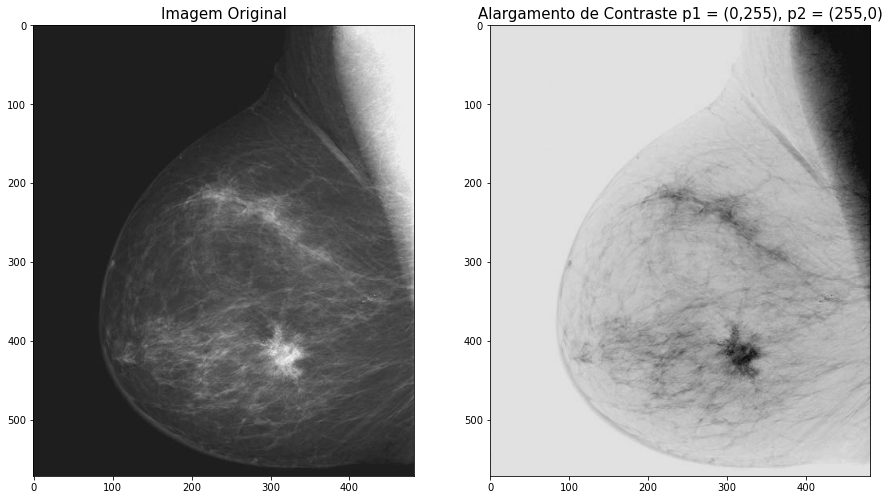

In [221]:
img = cv.imread('Fig0304(a)(breast_digital_Xray).tif')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB) 

img_out = np.zeros(img.shape, img.dtype)
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,15))

axs[0].imshow(img)
axs[0].set_title('Imagem Original', size=15)
cv.intensity_transform.contrastStretching(img, img_out, 0, 255, 255, 0)
axs[1].imshow(img_out)
axs[1].set_title('Alargamento de Contraste p1 = (0,255), p2 = (255,0)', size=15)

Text(0.5, 1.0, 'Alargamento de Contraste')

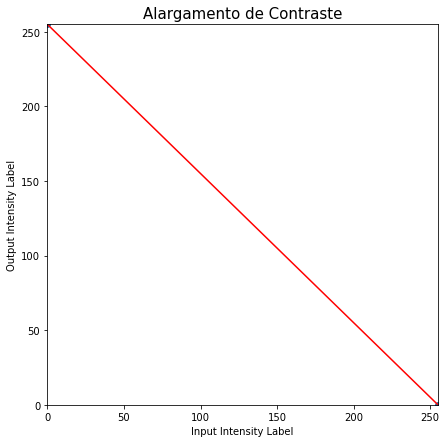

In [222]:
plt.figure(figsize=(7,7))
plt.plot([0,255], [255,0], 'red')
plt.scatter([0,255], [255,0])
plt.ylim((0,255))
plt.xlim((0,255))
plt.xlabel('Input Intensity Label')
plt.ylabel('Output Intensity Label')
plt.title('Alargamento de Contraste', size=15)

Text(0.5, 1.0, 'Alargamento de Contraste p1 = (128,191), p2 = (0,255)')

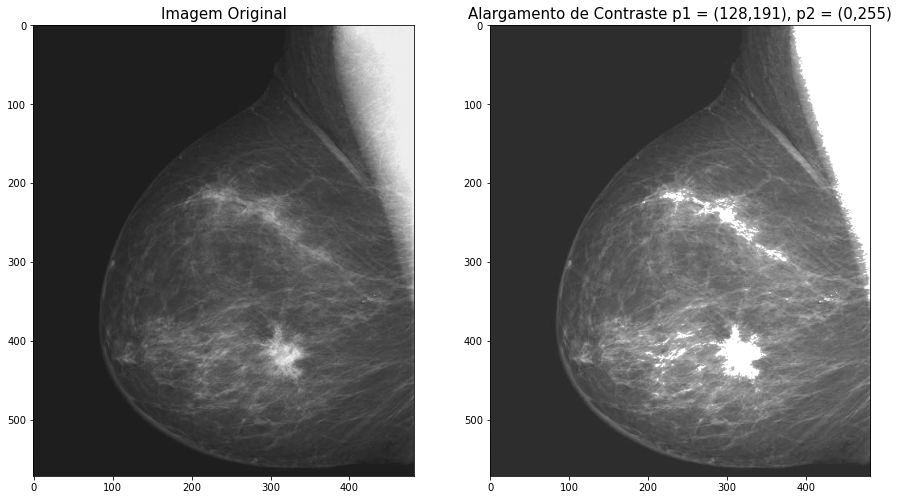

In [223]:
img_out = np.zeros(img.shape, img.dtype)
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,15))

axs[0].imshow(img)
axs[0].set_title('Imagem Original', size=15)
cv.intensity_transform.contrastStretching(img, img_out, 128, 191, 0, 255)
axs[1].imshow(img_out)
axs[1].set_title('Alargamento de Contraste p1 = (128,191), p2 = (0,255)', size=15)

Text(0.5, 1.0, 'Transformação de Potência, gama = 0.2')

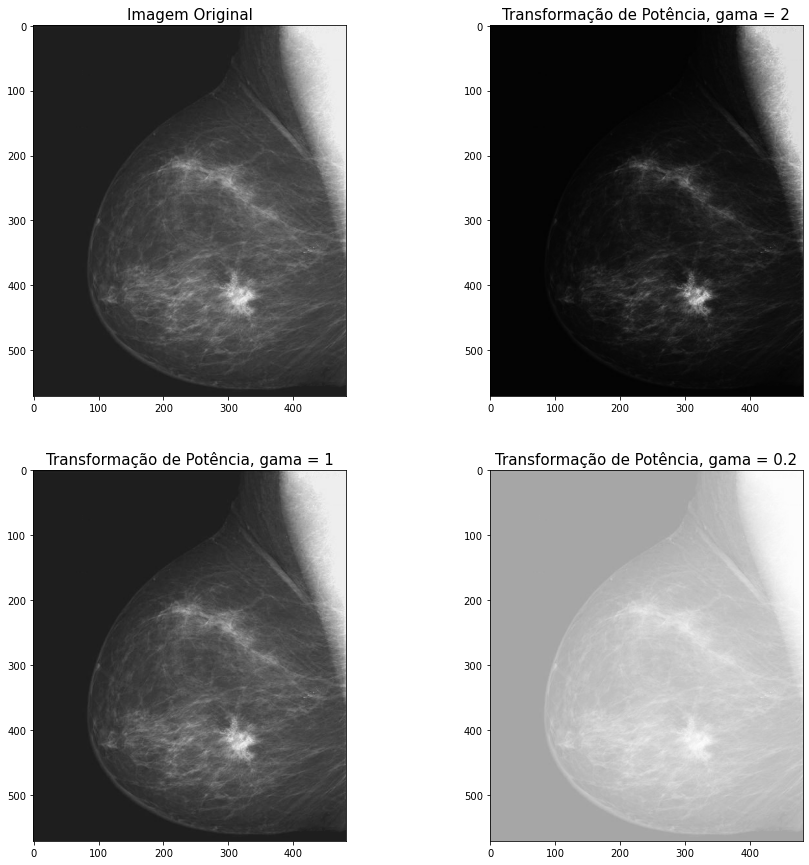

In [224]:
img_out = np.zeros(img.shape, img.dtype)
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,15))

axs[0,0].imshow(img)
axs[0,0].set_title('Imagem Original', size=15)
cv.intensity_transform.gammaCorrection(img, img_out, 2) 
axs[0,1].imshow(img_out)
axs[0,1].set_title('Transformação de Potência, gama = 2', size=15)
cv.intensity_transform.gammaCorrection(img, img_out, 1) 
axs[1,0].imshow(img_out)
axs[1,0].set_title('Transformação de Potência, gama = 1', size=15)
cv.intensity_transform.gammaCorrection(img, img_out, 0.2) 
axs[1,1].imshow(img_out)
axs[1,1].set_title('Transformação de Potência, gama = 0.2', size=15)

Text(0.5, 1.0, 'Transformação de Potência')

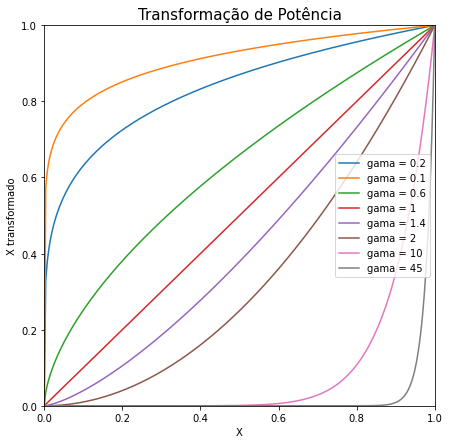

In [225]:
plt.figure(figsize=(7,7))
plt.plot(np.linspace(0, 1, 255), np.linspace(0, 1, 255) ** 0.2, label='gama = 0.2')
plt.plot(np.linspace(0, 1, 255), np.linspace(0, 1, 255) ** 0.1, label='gama = 0.1')
plt.plot(np.linspace(0, 1, 255), np.linspace(0, 1, 255) ** 0.6, label='gama = 0.6')
plt.plot(np.linspace(0, 1, 255), np.linspace(0, 1, 255) ** 1, label='gama = 1')
plt.plot(np.linspace(0, 1, 255), np.linspace(0, 1, 255) ** 1.4, label='gama = 1.4')
plt.plot(np.linspace(0, 1, 255), np.linspace(0, 1, 255) ** 2, label='gama = 2')
plt.plot(np.linspace(0, 1, 255), np.linspace(0, 1, 255) ** 10, label='gama = 10')
plt.plot(np.linspace(0, 1, 255), np.linspace(0, 1, 255) ** 45, label='gama = 45')
plt.scatter([0,255], [255,0])
plt.ylim((0,1))
plt.xlim((0,1))
plt.xlabel('X')
plt.ylabel('X transformado')
plt.legend()
plt.title('Transformação de Potência', size=15)

* <span style='color:green'>No alargamento de contraste cv.intensity_transform.contrastStretching (img_in, g1, 0, 255, 255, 0) é possível observar que ocorreu uma inversão de cores em relação a imagem original, efeito conhecido como imagem negativa. </span>
* <span style='color:green'>No alargamento de contraste cv.intensity_transform.contrastStretching (img_in, g2, 128, 191, 0, 255) é possível observar que as intensidades mais altas dos pixels obteve um maior contraste em relação a imagem original. Já os pixels com as intensidades mais baixas se mantiveram aproximadamente com o mesmo contraste em relação a imagem original. </span>
* <span style='color:green'>Na transformação de potência cv.intensity_transform.gammaCorrection (img, g3, 2), na qual foi utilizado um valor de $\gamma$ = 2, tal que $\gamma > 1$, é possível perceber que a imagem ficou mais escura. Por outro lado, fatores $\gamma < 1$ criam uma imagem mais clara com mais contraste nas áreas escuras. Essa última observação pode ser analisada no exemplo cv.intensity_transform.gammaCorrection(img, img_out, 0.2), na qual $\gamma = 0.2$</span>

## <span style="color:brown">4. Transformações logarítmicas</span> <a class="anchor" id="4"></a>
***

As transformações logarítmicas e de alargamento de contraste são ferramentas básicas para manipulação da faixa dinâmica da imagem. Os pixels de uma imagem podem ser submetidos a uma função de transformação logarítmica ponto-a-ponto, da forma $y = log ( 1 + x )$, através do comando **cv.intensity_transform.logTransform** da biblioteca do OpenCv

**Sintaxe:** `cv.intensity_transform.logTransform(img_in, img_out)`

**Descrição:** Dada uma imagem BGR ou em tons de cinza de entrada, aplique a transformação de log à imagem no domínio [0, 255] e retorne a imagem resultante.

**Parâmetros:**

`img_in` ->  imagem de entrada BGR ou em tons de cinza.  
`img_out` -> imagem resultante de transformações de log.


* <span style="color:blue">**c. Processe a imagem face.bmp usando as funções de transformação abaixo:**</span>

    * `F1=2f-40`
    * `F2=30log10(f+1)`
    * `F3=f^1.4`
    * `F4=f^0.6`

* <span style="color:blue">**d. Processe a imagem Fig0305(a)(DFT_no_log).tif usando a transformação logarítmica. Analise e comente os resultados.**</span>


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
<ipython-input-226-0c3c34cf2d2b>:12: RuntimeWarning: divide by zero encountered in log
  log_image = 30 * np.log(img + 1)
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Text(0.5, 1.0, '$y = f(x,y)^{0.6}$')

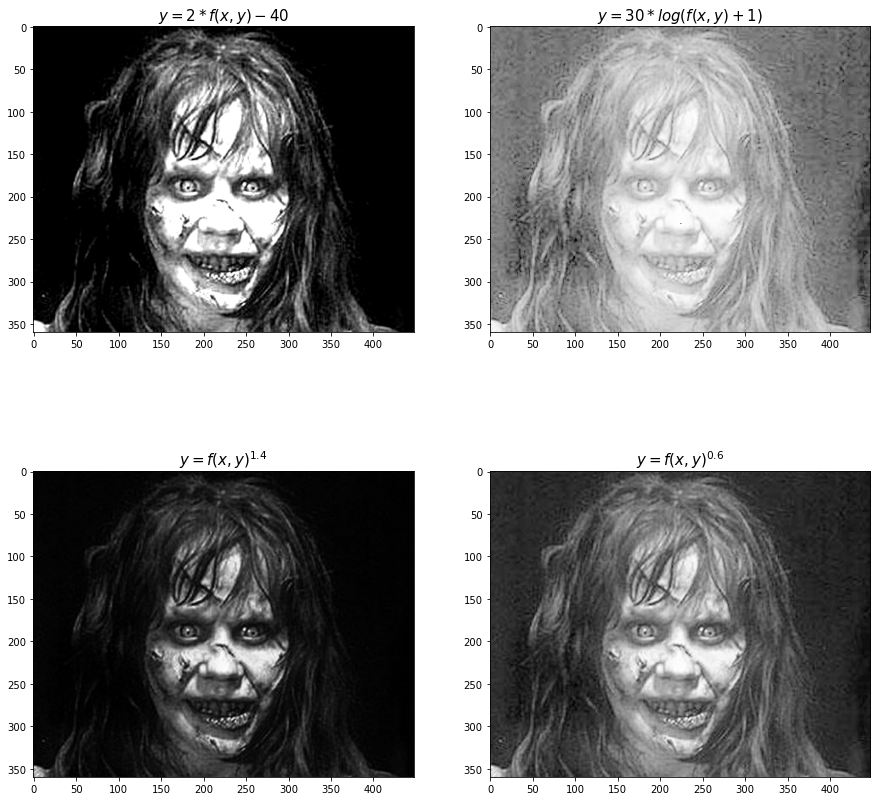

In [226]:
img = cv.imread('face.bmp')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

img_out = np.zeros(img.shape, img.dtype)

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,15))

axs[0,0].imshow((2 * img.astype('int32') - 40), vmin = img.min(), vmax = img.max())
axs[0,0].set_title('$y = 2 * f(x,y) - 40$', size=15) 

try:
    log_image = 30 * np.log(img + 1)
except RuntimeWarning: 
    pass

log_image = np.array(log_image, dtype=np.int32)

axs[0,1].imshow(log_image / log_image.max(), vmin = log_image.min(), vmax=log_image.max())
axs[0,1].set_title('$y = 30 * log(f(x,y) + 1)$', size=15) 
cv.intensity_transform.gammaCorrection(img, img_out, 1.4) 
axs[1,0].imshow(img_out, vmin=img_out.min(), vmax=img_out.max())
axs[1,0].set_title('$y = f(x,y)^{1.4}$', size=15)
cv.intensity_transform.gammaCorrection(img, img_out, 0.6)
axs[1,1].imshow(img_out, vmin=img_out.min(), vmax=img_out.max())
axs[1,1].set_title('$y = f(x,y)^{0.6}$', size=15)

Text(0.5, 1.0, 'Transformação Logarítmica')

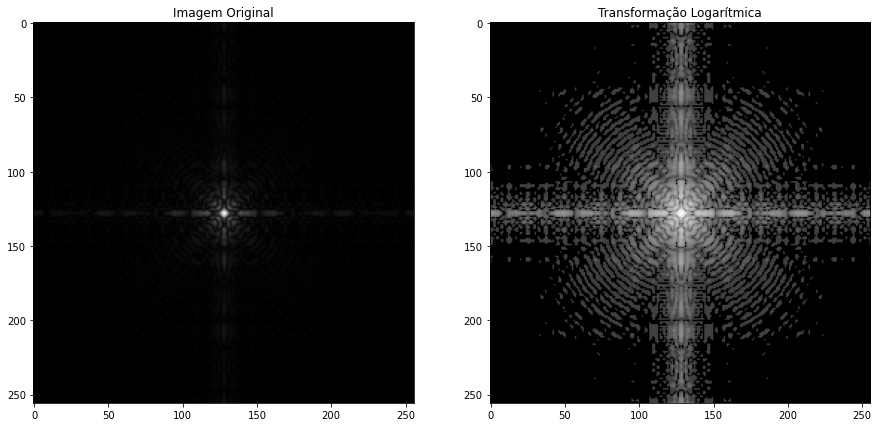

In [187]:
img = cv.imread('Fig0305(a)(DFT_no_log).tif')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img_out = np.zeros(img.shape, img.dtype)

cv.intensity_transform.logTransform(img, img_out)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,15))

axs[0].imshow(img)
axs[0].set_title('Imagem Original')
axs[1].imshow(img_out)
axs[1].set_title('Transformação Logarítmica')

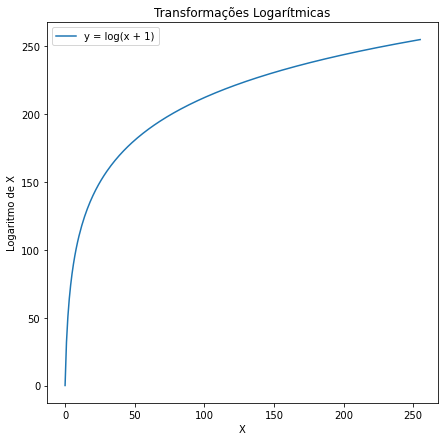

In [43]:
r = np.arange(0, 256)
c = 255 / (np.log(1 + 255))

plt.figure(figsize=(7,7))
plt.title('Transformações Logarítmicas')
plt.xlabel('X')
plt.ylabel('Logaritmo de X')
plt.plot(r, c * np.log(1 + r), label='y = log(x + 1)')
plt.legend()

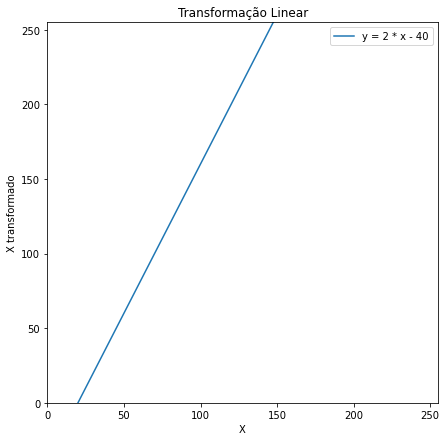

In [83]:
plt.figure(figsize=(7,7))
plt.plot(np.linspace(0, 255, 255),2 *np.linspace(0, 255, 255) - 40, label='y = 2 * x - 40')
plt.xlim((0,255))
plt.ylim((0,255))
plt.title('Transformação Linear')
plt.xlabel('X')
plt.ylabel('X transformado')
plt.legend()

* <span style="color:green">O resultado da aplicação da transformação logarítmica foi que a imagem ficou mais clara. Esse procedimento é semelhante com a transformação de potência quando $\gamma < 1$. Considerando o procedimento como $y =  c*log(f(x,y) + 1)$, sendo $c$ uma constante utilizada para dimensionar o intervalo da função log. Em linhas gerais, quanto maior o valor de $c$, mais clara ficará uma imagem.</span>
* <span style="color:green">Uma imagem em que pode se observar o sucesso do algoritmo de transformação logarítmica é na imagemFig0305(a)(DFT_no_log).tif, a qual foi possível observar alguns detalhes na imagem que não estavam visualmente perceptíveis.</span>

## <span style="color:brown">5. Cálculo do Histogramas</span> <a class="anchor" id="5"></a>
***

O histograma é uma ferramenta estatística, também  conhecida como distribuição de frequências,  que representa graficamente a distribuição dos dados em classes (ou bins). Podemos usar a função **calcHist** da biblioteca do OpenCV para calcular o histograma de uma imagem.

**Sintaxe**: `hist = cv.calcHist(images, channels, mask, histSize, ranges, accumulate)`

**Descrição**:  calcula o histograma de uma ou mais matrizes. 

**Parâmetros**:

`images` -> matriz de entrada (imagem de entrada)

`channels` -> Lista das dimensões dos canais usados para calcular o histograma

`mask` -> Máscara opcional. Se a matriz não estiver vazia, deve ser uma matriz de 8 bits com o mesmo tamanho das imagens. Os elementos da máscara não-zero marcam os elementos da matriz contados no histograma. 

`histSize` -> Histograma de saída, que é uma matriz densa ou esparsa dims -dimensional.

`ranges` -> Matriz com as dimensões da caixa de histograma.

`accmulate` -> Bandeira de acumulação (Nesse experimento usamos False).

Para maiores detalhes: https://docs.opencv.org/master/d6/dc7/group__imgproc__hist.html#ga4b2b5fd75503ff9e6844cc4dcdaed35d


Text(0, 0.5, 'Frequência')

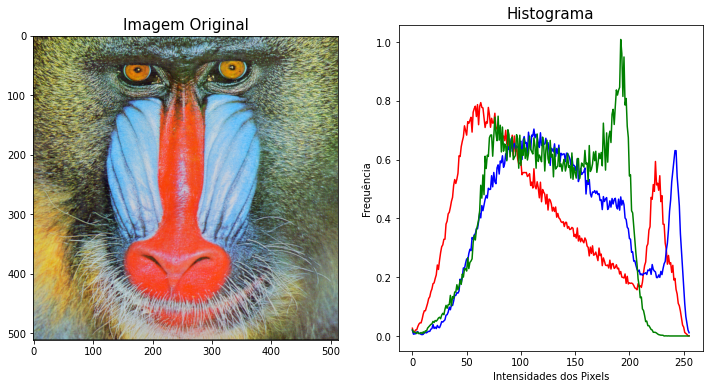

In [211]:
im = cv.imread('mandrill.tiff')
im = cv.cvtColor(im, cv.COLOR_BGR2RGB)

if im is None:
    print('Could not open or find the image:', args.input)
    exit(0)
    
im_planes = cv.split(im) 
 
histSize = 256

histRange = (0, 256) 
    
b_hist = cv.calcHist(im_planes, [0], None, [histSize], histRange, accumulate = False)
g_hist = cv.calcHist(im_planes, [1], None, [histSize], histRange, accumulate = False)
r_hist = cv.calcHist(im_planes, [2], None, [histSize], histRange, accumulate = False)    

[M, N, channels] = im.shape  
    
r_hist = 100 * r_hist/(M*N)
g_hist = 100 * g_hist/(M*N)
b_hist = 100 * b_hist/(M*N)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6,6))
axs[0].imshow(im, vmin=im.min(), vmax=im.max())
axs[0].set_title('Imagem Original', size=15)
fig.set_figheight(6)
fig.set_figwidth(12)
axs[1].plot(r_hist,'r')
axs[1].plot(b_hist,'b')
axs[1].plot(g_hist,'g')
axs[1].set_title('Histograma', size=15)
axs[1].set_xlabel('Intensidades dos Pixels')
axs[1].set_ylabel('Frequência')

## <span style="color:brown">6. Equalização de histogramas</span> <a class="anchor" id="6"></a>
***

Para aprimorar o contraste de uma imagem, uma das técnicas mais comuns é a equalização de seu histograma. Esta equalização reorganiza os valores de intensidade da imagem, produzindo imagens com histogramas mais lineares. Podemos usar a função **equalizeHist** da biblioteca do OpenCV para equalizar a imagem em escala de cinza.

**Sintaxe**: `im_out = cv.equalizeHist(im_in)`

**Descrição**:  Equaliza a imagem de entrada

**Parâmetros** 

`im_in` -> imagem a ser equalizada com 8 bits com apenas 1 canal  
`im_out` -> imagem equalizada do mesmo tipo e tamanho da imagem de entrada
 

Text(0.5, 1.0, 'Imagem YCrCb equalizada')

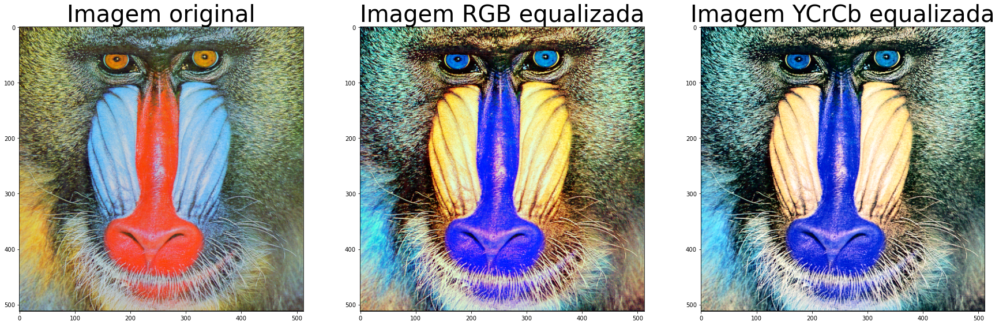

In [71]:
im_eq = np.zeros(im.shape, im.dtype)

im_eq[:,:,0] = cv.equalizeHist(im[:,:,0])
im_eq[:,:,1] = cv.equalizeHist(im[:,:,1])
im_eq[:,:,2] = cv.equalizeHist(im[:,:,2])

im_yuv_eq = cv.cvtColor(im, cv.COLOR_BGR2YCrCb)

im_yuv_eq[:,:,0] = cv.equalizeHist(im_yuv_eq[:,:,0])
#im_yuv_eq[:,:,1] = cv.equalizeHist(im_yuv_eq[:,:,1])
#im_yuv_eq[:,:,2] = cv.equalizeHist(im_yuv_eq[:,:,2])

im_eq = cv.cvtColor(im_eq, cv.COLOR_BGR2RGB)
im_yuv_eq = cv.cvtColor(im_yuv_eq, cv.COLOR_YCrCb2RGB)

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(30,30))
axs[0].imshow(im, vmin=im.min(), vmax=im.max())
axs[0].set_title("Imagem original", size=40)
axs[1].imshow(im_eq, vmin=im.min(), vmax=im.max())
axs[1].set_title("Imagem RGB equalizada",size=40)
axs[2].imshow(im_yuv_eq, vmin=im.min(), vmax=im.max())
axs[2].set_title("Imagem YCrCb equalizada", size=40)

* <span style="color:blue">**e. Converta a imagem "babuino.jpg" para nível de cinza e equalize essa imagem. Mostre a imagem em nível de cinza e a imagem equalizada e seus respectivo histogramas. Descreva o que ocorreu com a imagem equalizada.**</span>

* <span style="color:blue">**f. O que acontece se a imagem equalizada for equalizada diversas vezes? Teste e comente os resultados.**</span>

Text(0.5, 1.0, 'Imagem em Nível de Cinza')

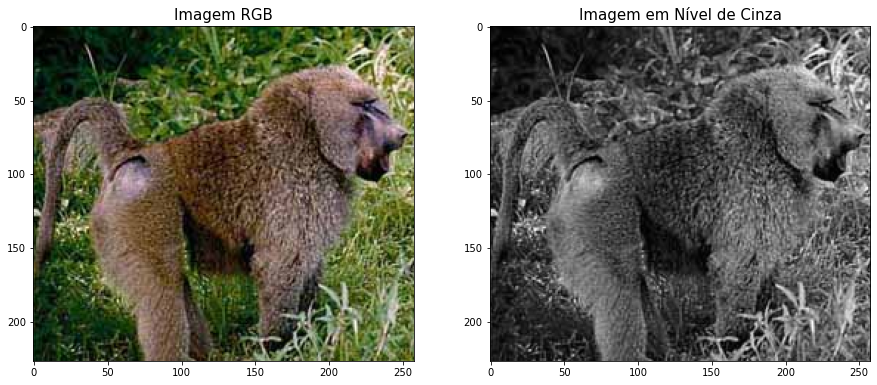

In [208]:
img = cv.imread('babuino.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

gray_img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,15))

axs[0].imshow(img)
axs[0].set_title('Imagem RGB' , size=15)
axs[1].imshow(gray_img, 'gray')
axs[1].set_title('Imagem em Nível de Cinza', size=15)

Text(0, 0.5, 'Frequência')

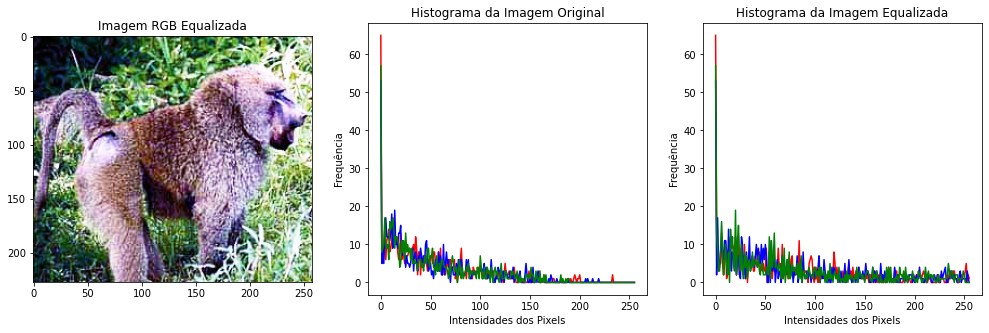

In [212]:
im_rgb_eq = np.zeros(img.shape, img.dtype)
im_rgb_eq[:,:,0] = cv.equalizeHist(img[:,:,0])
im_rgb_eq[:,:,1] = cv.equalizeHist(img[:,:,1])
im_rgb_eq[:,:,2] = cv.equalizeHist(img[:,:,2])

[M, N, channels] = im_rgb_eq.shape

r_hist_eq = cv.calcHist(im_rgb_eq, [0], None, [256], (0,256), accumulate = False)
g_hist_eq = cv.calcHist(im_rgb_eq, [1], None, [256], (0,256), accumulate = False)
b_hist_eq = cv.calcHist(im_rgb_eq, [2], None, [256], (0,256), accumulate = False) 

#r_hist_eq = 1000 * r_hist_eq/(M*N)
#g_hist_eq = 1000 * g_hist_eq/(M*N)
#b_hist_eq = 1000 * b_hist_eq/(M*N)  

r_hist = cv.calcHist(img, [0], None, [256], (0,256), accumulate = False)
g_hist = cv.calcHist(img, [1], None, [256], (0,256), accumulate = False)
b_hist = cv.calcHist(img, [2], None, [256], (0,256), accumulate = False) 

#r_hist = 1000 * r_hist/(M*N)
#g_hist = 1000 * g_hist/(M*N)
#b_hist = 1000 * b_hist/(M*N)  

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(15,15))
axs[0].imshow(im_rgb_eq)
axs[0].set_title('Imagem RGB Equalizada')
fig.set_figheight(5)
fig.set_figwidth(17)
axs[1].plot(r_hist,'r')
axs[1].plot(b_hist,'b')
axs[1].plot(g_hist,'g')
axs[1].set_title('Histograma da Imagem Original')
axs[1].set_xlabel('Intensidades dos Pixels')
axs[1].set_ylabel('Frequência')
axs[2].plot(r_hist_eq,'r')
axs[2].plot(b_hist_eq,'b')
axs[2].plot(g_hist_eq,'g')  
axs[2].set_title('Histograma da Imagem Equalizada')
axs[2].set_xlabel('Intensidades dos Pixels')
axs[2].set_ylabel('Frequência')

Text(0, 0.5, 'Frequência')

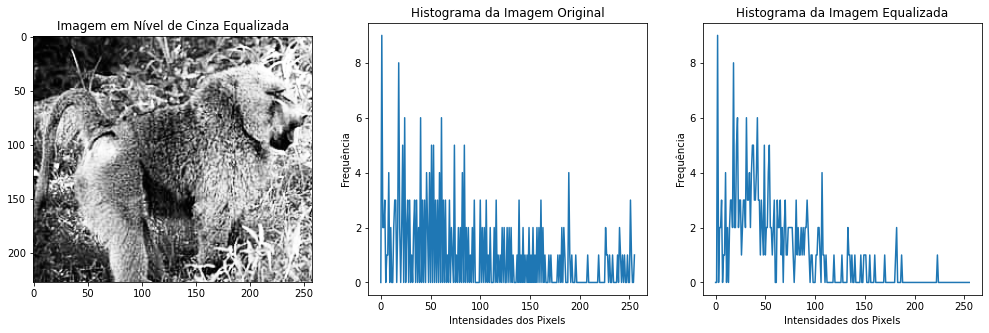

In [214]:
im_gray_eq = cv.equalizeHist(gray_img)

[M, N, channels] = im_rgb_eq.shape

gray_hist_eq = cv.calcHist(im_gray_eq, [0], None, [256], (0,256), accumulate = False) 
#gray_hist_eq = 100 * gray_hist_eq/(M*N)

gray_hist = cv.calcHist(gray_img, [0], None, [256], (0,256), accumulate = False) 
#gray_hist = 100 * gray_hist/(M*N)

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(15,15))
axs[0].imshow(im_gray_eq, 'gray')
axs[0].set_title('Imagem em Nível de Cinza Equalizada')
fig.set_figheight(5)
fig.set_figwidth(17)
axs[1].plot(gray_hist_eq)
axs[1].set_title('Histograma da Imagem Original')
axs[1].set_xlabel('Intensidades dos Pixels')
axs[1].set_ylabel('Frequência')
axs[2].plot(gray_hist)
axs[2].set_title('Histograma da Imagem Equalizada')
axs[2].set_xlabel('Intensidades dos Pixels')
axs[2].set_ylabel('Frequência')

* <span style="color:green">Ao aplicar a equalização de histograma, houve uma distribuição dos valores que correspondem a intensidades dos pixels da imagem. Essa distribuição é feita de modo que as diferenças mais acentuadas na imagem sejam atenuadas. Assim, detalhes não visíveis tendem a ser acentuados.</span>
* <span style="color:green">A aplicação dessa equalização nos 3 canais de uma imagem RGB prejudicou as cores originais da imagem, já que ela foi realizada em cada um dos canais de forma independente. Algumas alterações no algoritmo de equalização por histograma permitem resolver esse problema.</span>
* <span style="color:green">A aplicação da equalização de histograma na imagem em escala de cinza foi a mais ideal para o algoritmo testado nesse experimento, pois a imagem é representada originalmente apenas por um canal.</span>

Text(0.5, 1.0, 'Quarta Equalização')

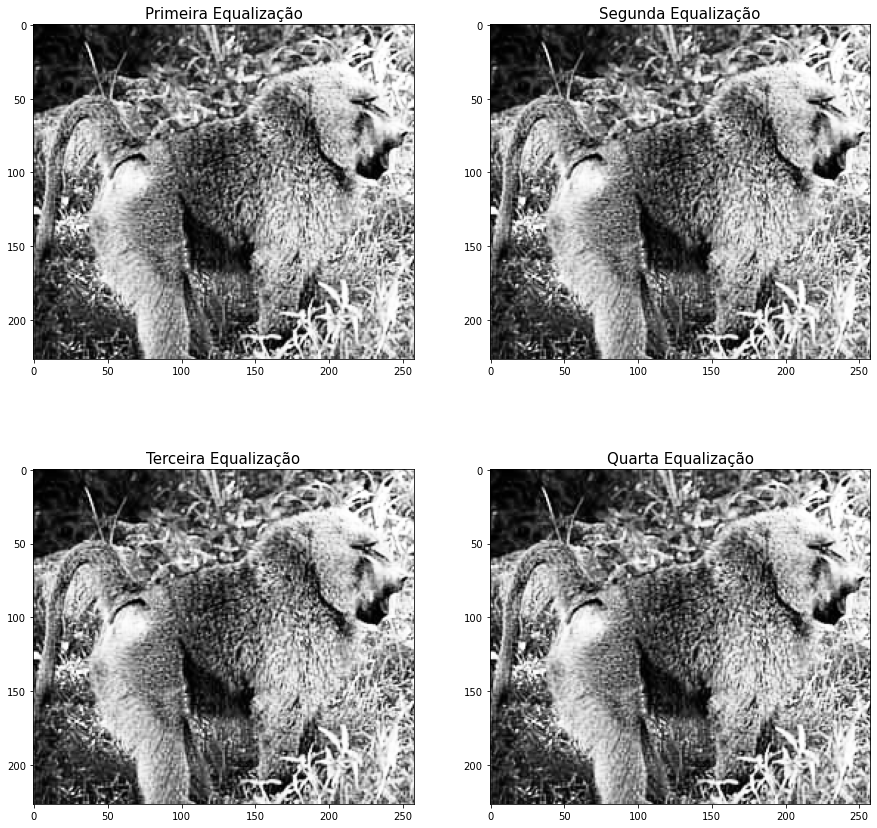

In [207]:
im_gray_eq = cv.equalizeHist(gray_img)
im_gray_eq1 = cv.equalizeHist(im_gray_eq)
im_gray_eq2 = cv.equalizeHist(im_gray_eq1)
im_gray_eq3 = cv.equalizeHist(im_gray_eq2)

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,15))

axs[0,0].imshow(im_gray_eq, 'gray')
axs[0,0].set_title('Primeira Equalização', size=15)
axs[0,1].imshow(im_gray_eq1, 'gray')
axs[0,1].set_title('Segunda Equalização', size=15)
axs[1,0].imshow(im_gray_eq2, 'gray')
axs[1,0].set_title('Terceira Equalização', size=15)
axs[1,1].imshow(im_gray_eq3, 'gray')
axs[1,1].set_title('Quarta Equalização', size=15)

* <span style="color:green">Ao aplicar a equalização de histograma de forma consecutiva, é possível observar que nenhuma alteração ocorre, pois os valores das intensidades dos pixels já estão distribuidos de forma ótima.</span>

## <span style="color:brown">7. Filtragem espacial</span> <a class="anchor" id="7"></a>
***

A operação de filtragem espacial é realizada pela função **filter2D()** da bibioteca OpenCV, que realiza a operação de convolução de uma imagem com uma máscara (elemento estruturante).

**Sintaxe:** `im_out = cv.filter2D(im_in, ddepth, kernel)`

**Descrição:** Realiza a operação de filtragem linear entre a imagem de entrada e a máscara

**Parametros**:

`im_in`	-> imagem de entrada.

`im-out`	-> imagem de saída de mesmo tamanho e o mesmo número de canais que im_in.

`ddepth`	-> profundidade desejada da imagem de destino.

`kernel`	-> máscara de convolução (ou melhor, um kernel de correlação), uma matriz de ponto flutuante de um único canal; se você quiser aplicar diferentes núcleos a diferentes canais, divida a imagem em planos de cores separados  e processe-os individualmente.




Text(0.5, 1.0, 'Imagem filtrada com o filtro da média')

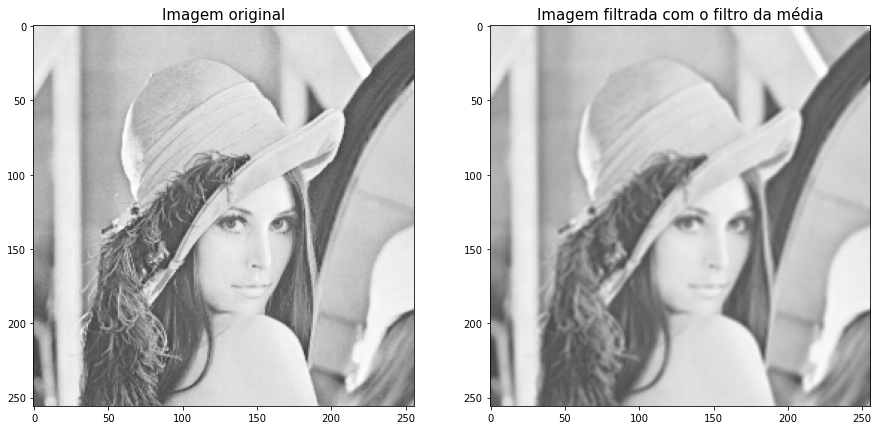

In [206]:
im=cv.imread('lenna.tif')

if im is None:
    print('Could not open or find the image:', args.input)
    exit(0)

kernel = np.ones((3,3),np.float32)/9

im_out = cv.filter2D(im,-1,kernel)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,15))
axs[0].imshow(im)
axs[0].set_title("Imagem original", size=15)
axs[1].imshow(im_out)
axs[1].set_title("Imagem filtrada com o filtro da média",size=15)

## <span style="color:brown">8. Suavização de imagens</span> <a class="anchor" id="8"></a>
***

Uma das aplicações mais comuns das técnicas de processamento de imagens está nas áreas de remoção de ruídos e aprimoramento da qualidade de uma imagem. Nesta prática abordaremos duas técnicas de remoção de ruído, que equivalem a filtros passa-baixa, que são:
* **Filtragem pela média**: nesta técnica, o pixel central de uma janela (normalmente 3 x 3) é substituído pela média dos valores de intensidade de seus 8 vizinhos. Isso pode ser feito plea função `im_out = cv.blur(im_in, size)`.
* **Filtragem pela mediana**: nesta técnica, o pixel central de uma janela (normalmente 3 x 3) é substituído pela mediana dos valores de intensidade de seus 8 vizinhos. Isso pode ser feito plea função `im_out = cv.medianBlur(im_in, ksize)`.

* **Filtragem Gaussiana**: nesta técnica, o pixel central de uma janela (normalmente 3 x 3) é substituído pelo resultado da convolucão da imagem com uma máscara Gaussiana com determinado desvio padrão. Isso pode ser feito plea função `im_out = cv.GaussianBlur(im_in, size, sigma)`.

Para maiores detalhes dessas funções consulte https://docs.opencv.org/4.5.2/index.html

Text(0.5, 1.0, 'Filtro Gaussiano')

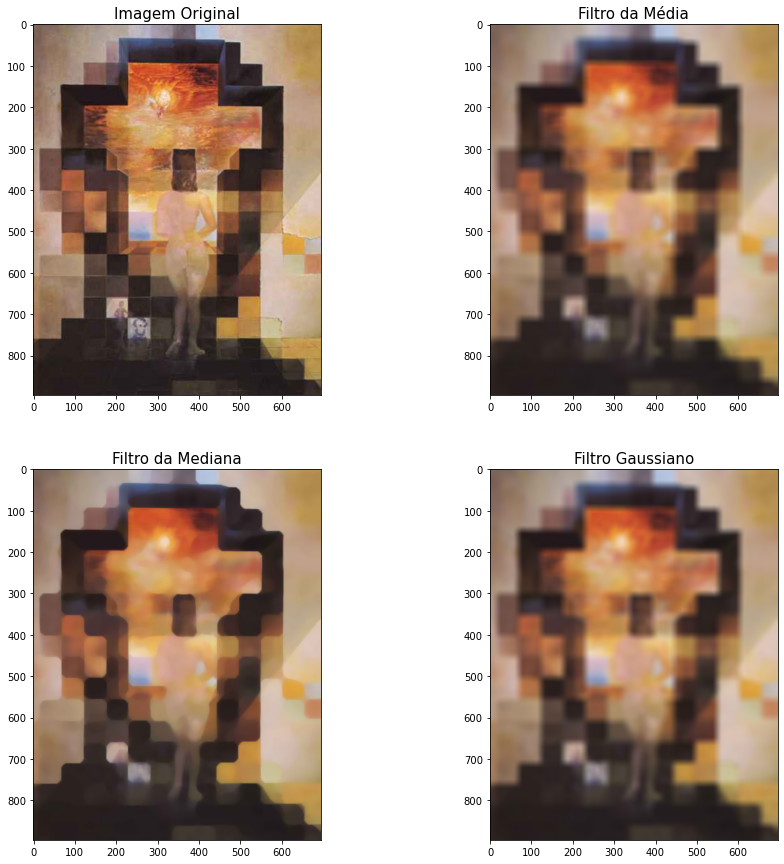

In [213]:
im=cv.imread('dali.png')

if im is None:
    print('Could not open or find the image:', args.input)
    exit(0)

nsize=21
size = (nsize,nsize)
sigma = 10
im_out1 = cv.blur(im,size)
im_out2 = cv.medianBlur(im, nsize)
im_out3 = cv.GaussianBlur(im, size, sigma)

im = cv.cvtColor(im, cv.COLOR_BGR2RGB)
im_out1 = cv.cvtColor(im_out1, cv.COLOR_BGR2RGB)
im_out2 = cv.cvtColor(im_out2, cv.COLOR_BGR2RGB)
im_out3 = cv.cvtColor(im_out3, cv.COLOR_BGR2RGB)

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,15))
axs[0,0].imshow(im)
axs[0,0].set_title("Imagem Original", size=15)
axs[0,1].imshow(im_out1)
axs[0,1].set_title("Filtro da Média",size=15)
axs[1,0].imshow(im_out2)
axs[1,0].set_title("Filtro da Mediana",size=15)
axs[1,1].imshow(im_out3)
axs[1,1].set_title("Filtro Gaussiano",size=15)

* <span style="color:blue">**g. nessa questão vamos avaliar os filtros da média, da mediana e o gaussiano na filtragem de imagens com ruído sal e pimenta na imagem boat.512.tiff. Portanto incialmente aplique o ruido sal e pimenta na imagem, para tanto utilize o seguinte comando im_noise = sp_noise(im, 0.05). A seguir, utilize os filtros da média, da mediana e o gaussiano para filtrar esse ruído, escolhar os seus parâmetros com cuidado, para reduzir o ruído sem comprometer a imagem.**</span>

Text(0.5, 1.0, 'Imagem Ruidosa')

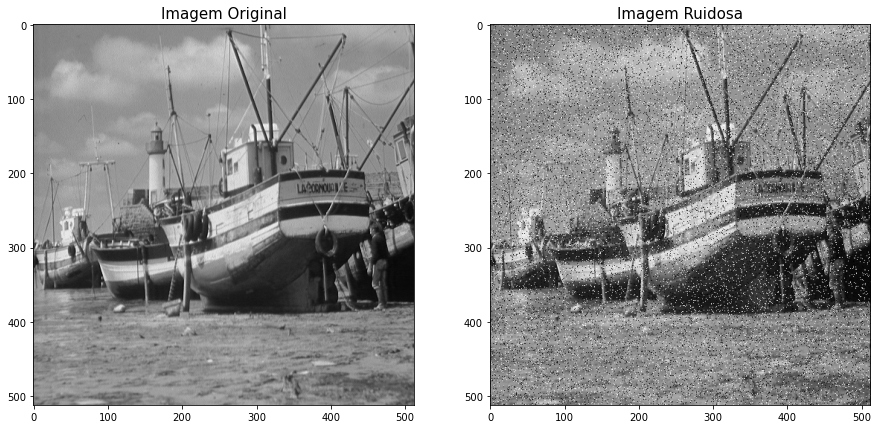

In [204]:
img = cv.imread('boat.512.tiff')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

img_noise = sp_noise(img, 0.05)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,15))
axs[0].imshow(img)
axs[0].set_title("Imagem Original", size=15)
axs[1].imshow(img_noise)
axs[1].set_title("Imagem Ruidosa", size=15)

Text(0.5, 1.0, 'Filtro Gaussiano')

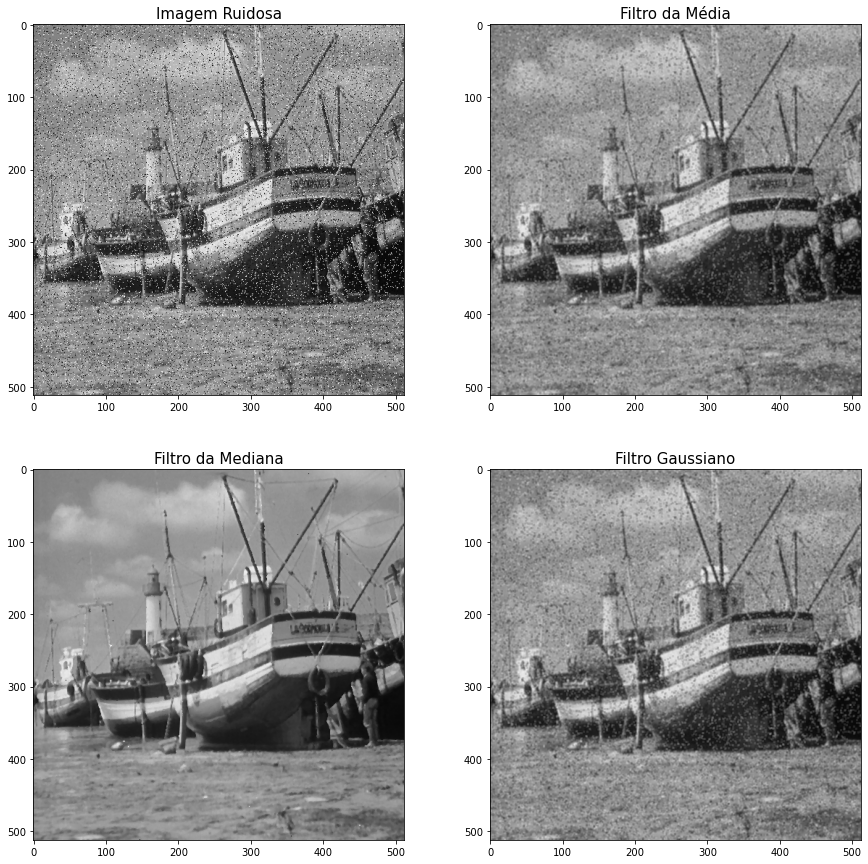

In [203]:
nsize = 3
size = (nsize,nsize)
sigma = 10
im_out1 = cv.blur(img_noise,size)
im_out2 = cv.medianBlur(img_noise, nsize)
im_out3 = cv.GaussianBlur(img_noise, size, sigma)

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,15))
axs[0,0].imshow(img_noise)
axs[0,0].set_title("Imagem Ruidosa", size=15)
axs[0,1].imshow(im_out1)
axs[0,1].set_title("Filtro da Média",size=15)
axs[1,0].imshow(im_out2)
axs[1,0].set_title("Filtro da Mediana",size=15)
axs[1,1].imshow(im_out3)
axs[1,1].set_title("Filtro Gaussiano",size=15)

* <span style="color:green">Observando os resultados das imagens com os filtros de suavização, percebemos que o filtro da mediana foi o mais eficaz para reduzir o ruído na imagem. Um motivo para tal eficácia nesse procedimento é que os ruídos gerados sempre são representados por pixels com intensidades muito próximas a valores altos (255) ou baixos (0). Essas intensidades em meio a um conjunto de elementos de um filtro raramente são os resultados da mediana, justificando a eficácia desse procedimento de suavização para redução de ruídos.</span>

## <span style="color:brown">9. Aguçamento de imagens</span> <a class="anchor" id="9"></a>
***

As bordas e outras mudanças abruptas de intensidade em imagens são associadas a componentes de alta frequência, o aguçamento de imagens tem como objetivo tem como objetivo salientar essas saliências nas imagens. Essas regiões podem ser filtros que realizam a diferenciação de uma imagem, realçando as bordas e outras descontinuidades (**como o ruído**) enquanto atenua as áreas com intensidades de variação mais suave. O gradiente de sobel consite na operação de convloução da imagem com  duas máscaras $g_x$ e $g_y$. Após o processo de convolução deve-se calcular o valor absoluto do resultado. 
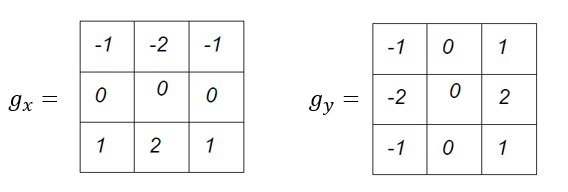



Text(0.5, 1.0, 'Imagem filtrada com o filtro $|Gx|+|Gy|$')

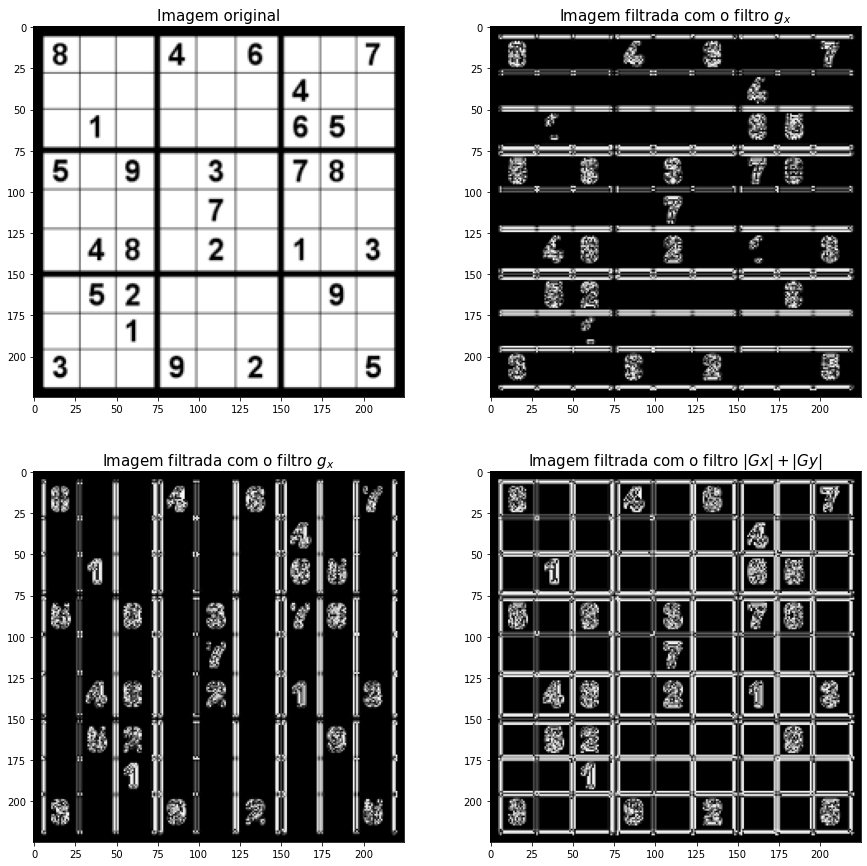

In [197]:
im=cv.imread('sudoku.png')
if im is None:
    print('Could not open or find the image:', args.input)
    exit(0)
    
im1 = im.astype(np.int16)
    
gx = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])
gy = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])

Gx = abs(cv.filter2D(im1,-1,gx))
Gy = abs(cv.filter2D(im1,-1,gy))
im_out = Gx+Gy

Gx = Gx.astype(np.uint8)
Gy = Gy.astype(np.uint8)
im_out = im_out.astype(np.uint8)

#show image
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,15))
axs[0,0].imshow(im)
axs[0,0].set_title("Imagem original", size=15)
axs[0,1].imshow(Gx)
axs[0,1].set_title("Imagem filtrada com o filtro $g_x$",size=15)
axs[1,0].imshow(Gy)
axs[1,0].set_title("Imagem filtrada com o filtro $g_x$",size=15)
axs[1,1].imshow(im_out)
axs[1,1].set_title("Imagem filtrada com o filtro $|Gx|+|Gy|$",size=15)

* <span style="color:blue">**h. Implemente a filtragem conforme foi descrito na aula e por conviniência mostrado no slide abaixo. E teste sua implementação na imagem Fig0340(a)(dipxe_text).tif. Utilize como filtro passa baixa o filtro gaussiano**</span>

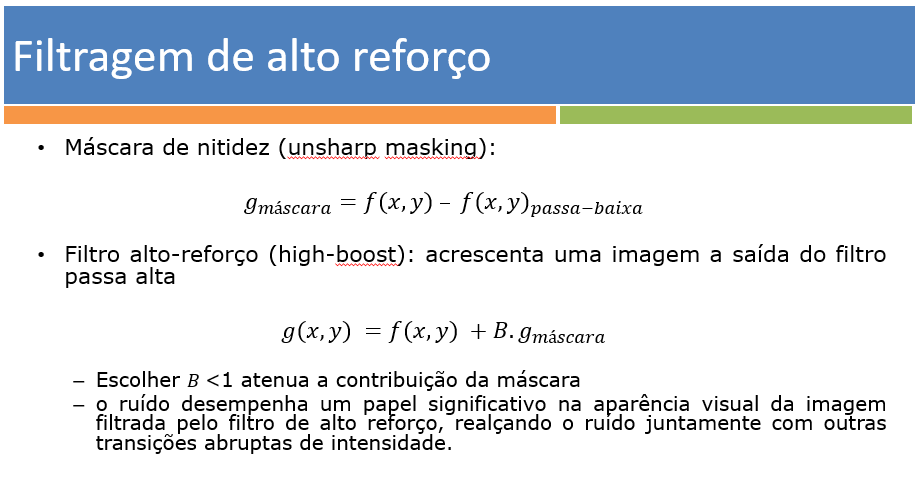


Text(0.5, 1.0, 'Filtro de Nitidez + Alto-reforço')

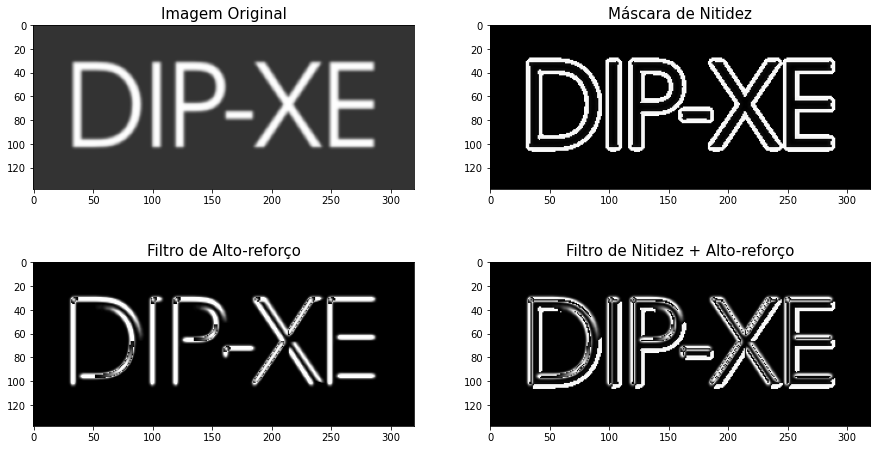

In [4]:
img = cv.imread('imagens/Fig0340(a)(dipxe_text).tif')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

low = cv.GaussianBlur(img, (3,3), 30)
unsharp_masking = img - low

gx = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])
gy = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
Gx = abs(cv.filter2D(img,-1,gx))
Gy = abs(cv.filter2D(img,-1,gy))
high_boost = Gx+Gy

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,8))
axs[0,0].imshow(img)
axs[0,0].set_title("Imagem Original", size=15)
axs[0,1].imshow(unsharp_masking)
axs[0,1].set_title("Máscara de Nitidez", size=15)
axs[1,0].imshow(high_boost)
axs[1,0].set_title("Filtro de Alto-reforço", size=15)
axs[1,1].imshow(unsharp_masking + high_boost)
axs[1,1].set_title("Filtro de Nitidez + Alto-reforço", size=15)

***
![marvel](https://user-images.githubusercontent.com/58775072/135618990-92198239-b4bf-4ce9-aa70-2b3df34e3bde.gif)